
<div style="border:solid green 2px; padding: 20px">

👋 **¡Hola! Soy Dot, tu revisor de IA.**

He completado la primera revisión de tu código. A continuación, encontrarás mis comentarios y sugerencias de mejora.

**¿Qué debes hacer ahora?**

1. **Revisar:** Lee mis comentarios en el notebook más abajo.
2. **Decidir:**
* **¿Estás de acuerdo con el feedback?** ¡Genial! Actualiza tu código según las sugerencias.
* **¿No estás de acuerdo o crees que es un error?** ¡No hay problema! Puedes dejar tu código exactamente como está.


3. **Volver a enviar:** Envía tu proyecto de nuevo. **Tu próxima iteración será revisada por un experto humano**, independientemente de si hiciste cambios o no.

-------------------------------------------------------------------------------------------------------------
Mis comentarios están más abajo. **Te pido amablemente que no los muevas, modifiques ni elimines**.

Verás mis comentarios resaltados en cuadros verdes, amarillos o rojos como estos:

<div class="alert alert-block alert-success">
<b>Reviewer's comment, Iteration X</b> <a class="tocSkip"></a>

Correcto. Todo se ha hecho exitosamente.
</div>

<div class="alert alert-block alert-warning">
<b>Reviewer's comment, Iteration X</b> <a class="tocSkip"></a>

Observaciones. Algunas recomendaciones.
</div>

<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration X</b> <a class="tocSkip"></a>

Necesita corrección. El bloque requiere algunas correcciones.
</div>



<div class="alert alert-block alert-warning">
<b>Review General. (Iteracion 2)</b>

Hola Cristina, soy Santiago estoy encargado de la segunda revision. Antes de entrar al detalle, quiero reconocer los avances muy solidos — la mayoria de los dangers de IT1 quedaron resueltos:
- ✅ <b>c28 danger (churn_date):</b> convertida a datetime con NaT para usuarios activos y columna has_churned. ✅
- ✅ <b>c42 danger (llamadas de 0 min):</b> se verificaron (26,834 registros) y se justifica mantenerlas como no facturables. ✅
- ✅ <b>c60 warning (mb_used validation):</b> validaciones de negativos y ceros de internet agregadas en c59. ✅
- ✅ <b>c79 warning (gb_included sin ceil):</b> eliminado el ceil de gb_included — solo se aplica al gb_used. ✅
- ✅ <b>c87 danger (stats de filtered data):</b> se toma la decision explicita de excluir meses sin llamadas con justificacion. ✅
- ✅ <b>c102/c104 danger (revenue sin stats):</b> c101 tiene mean/var/std/median/min/max por plan. ✅
- ✅ <b>c117 danger (conclusion con brackets):</b> conclusion general escrita con texto propio en c116. ✅
- ✅ Exec counts 1-39 perfectamente consecutivos. ✅

Hay <b>un punto que sigue bloqueando la aprobacion</b>. Lo detallo abajo.
</div>


<div class="alert alert-block alert-success">
<b>Review General. (Iteracion 3)</b>

Hola Cristina! Aqui va la tercera revision — y es la definitiva. El proyecto esta <b>aprobado</b>. 🎉

El unico blocker de IT2 quedo resuelto: la celda 104 (exec=45) tiene estadisticas descriptivas completas de internet por plan (mean, variance, std, median, min, max, count), histograma comparativo y boxplot. Exactamente lo que el danger de IT1 e IT2 pedian. ✅

Observaciones menores en amarillo abajo.
</div>


# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.

<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Todavía hay varios prompts de plantilla entre corchetes. Por favor, elimina todo el texto de guía entre corchetes en todo el notebook y reemplázalo con una breve introducción propia que indique el objetivo del proyecto y los pasos principales del análisis que seguirás.

</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteracion 2)</b>

La celda 2 todavia tiene el texto de guia de plantilla entre corchetes. Las conclusiones, la preparacion de datos y los graficos estan muy bien — solo falta eliminar ese bloque de instrucciones. No bloquea la aprobacion dado el resto del analisis.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteracion 3)</b>

La celda 2 todavia tiene el texto de guia de plantilla entre corchetes. Sigue siendo cosmtico — no bloquea la aprobacion, pero es el ultimo pendiente de limpieza.
</div>


## Inicialización

In [1]:
# Cargar todas las librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st



## Cargar datos

In [2]:
# Carga los archivos de datos en diferentes DataFrames

df_calls = pd.read_csv('/datasets/megaline_calls.csv')
df_internet = pd.read_csv('/datasets/megaline_internet.csv')
df_messages = pd.read_csv('/datasets/megaline_messages.csv')
df_plans = pd.read_csv('/datasets/megaline_plans.csv')
df_users = pd.read_csv('/datasets/megaline_users.csv')





## Preparar los datos

Comenzamos con la lectura y preparación de los datos.

## Tarifas

In [3]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas


print(df_plans.head())
print(df_plans.info())




   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   pla

In [4]:

# Imprime una muestra de los datos para las tarifas
print(df_plans.sample())


   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  


[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?] No encuentro inconsistencias ni errores en los datos. Los dtypes concuerdan con el tipo de dato de cada columna. Tampoco hay valores nulos ni errores tipográficos. Quizá lo que cambiaría sería en plan_name sería iniciar los nombres con mayúscula, pensando que más adelante lo pueda usar en algún reporte de manera profesional.

## Corregir datos

Según las observaciones de las lecturas, procedemos con la correción.

In [5]:
#Cambiaré el plan name para iniciar con mayúsculas. No es un error en sí, pero por estética cuando haya que reportar

df_plans['plan_name'] = df_plans['plan_name'].str.title()
print(df_plans.head())



   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      Surf  
1               70           7             0.01            0.01  Ultimate  


## Enriquecer los datos

Para enriquecer los datos, añadimos algunas columnas que nos harán más fácil la lectura.

In [6]:
#Voy a cambiar el orden de las columnas para que el nombre del plan sea la primera y el importe del pago mensual la segunda y sea más fácil leer el resto de los datos, así como a la hora de presentar algún reporte

df_plans = df_plans[['plan_name', 'usd_monthly_pay', 'messages_included', 'mb_per_month_included', 'minutes_included', 'usd_per_gb', 'usd_per_message', 'usd_per_minute']]
print(df_plans.head())

  plan_name  usd_monthly_pay  messages_included  mb_per_month_included  \
0      Surf               20                 50                  15360   
1  Ultimate               70               1000                  30720   

   minutes_included  usd_per_gb  usd_per_message  usd_per_minute  
0               500          10             0.03            0.03  
1              3000           7             0.01            0.01  


<div class="alert alert-block alert-success">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Buen paso de enriquecimiento: reordenar las columnas mejora la legibilidad sin cambiar los datos, lo que facilita seguir las fusiones (merges) y el análisis posteriores.

</div>


## Usuarios/as

In [7]:
# Imprime la información general/resumida sobre el DataFrame de usuarios
print(df_users.head())
print(df_users.info())


   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36   Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                          Tulsa, OK MSA   
4     1004    Leonila   Thompson   40        Seattle-Tacoma-Bellevue, WA MSA   

     reg_date      plan churn_date  
0  2018-12-24  ultimate        NaN  
1  2018-08-13      surf        NaN  
2  2018-10-21      surf        NaN  
3  2018-01-28      surf        NaN  
4  2018-05-23      surf        NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    

In [8]:
# Imprime una muestra de datos para usuarios
print(df_users.sample(15))


     user_id first_name last_name  age  \
126     1126   Jermaine   Mcguire   68   
416     1416       Deja      Moss   25   
451     1451     Lenard   Harding   53   
419     1419      Bryon    Gordon   45   
197     1197        Lon    Parker   56   
106     1106       Eddy  Garrison   47   
192     1192      Korey   Goodwin   36   
272     1272     Ernest   Mercado   23   
198     1198       Russ     Horne   69   
189     1189   Terrence     Smith   75   
178     1178   Charlsie      Reid   53   
225     1225  Margarito    Barker   41   
172     1172     Weldon  Robinson   72   
299     1299     Keitha  Harrison   64   
141     1141    Kirstie    Hodges   46   

                                            city    reg_date      plan  \
126       Chicago-Naperville-Elgin, IL-IN-WI MSA  2018-06-02  ultimate   
416  Minneapolis-St. Paul-Bloomington, MN-WI MSA  2018-10-03      surf   
451        Charlotte-Concord-Gastonia, NC-SC MSA  2018-02-15  ultimate   
419                Phoenix-Mesa

[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?] Observamos que la columna reg_date es de tipo object, cuando debería de ser de tipo fecha. También hay valores ausentes en churn_date. En los siguientes pasos corregiré cambiando el tipo de dato y sustituyendo los valores ausentes (son 466 y no creo que debería de eliminarlos).

### Corregir los datos

Corregimos datos según las observaciones de los resultados arrojados. Cambiamos churn date a datetime y añadimos una columna adicional para indicar si el usuario ha hecho o no churn.

In [9]:
# Cambiar tipo de dato de columna reg_date

df_users['reg_date'] = pd.to_datetime(df_users['reg_date'])
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'], errors='coerce')
df_users['has_churned'] = df_users['churn_date'].notna()
print(df_users.head(15))
print(df_users.info())

    user_id first_name  last_name  age  \
0      1000   Anamaria      Bauer   45   
1      1001     Mickey  Wilkerson   28   
2      1002     Carlee    Hoffman   36   
3      1003   Reynaldo    Jenkins   52   
4      1004    Leonila   Thompson   40   
5      1005      Livia    Shields   31   
6      1006     Jesusa   Bradford   73   
7      1007    Eusebio      Welch   42   
8      1008      Emely    Hoffman   53   
9      1009      Gerry     Little   19   
10     1010     Wilber      Blair   52   
11     1011     Halina      Henry   73   
12     1012    Jonelle    Mcbride   59   
13     1013    Nicolas     Snider   50   
14     1014    Edmundo      Simon   61   

                                         city   reg_date      plan churn_date  \
0       Atlanta-Sandy Springs-Roswell, GA MSA 2018-12-24  ultimate        NaT   
1             Seattle-Tacoma-Bellevue, WA MSA 2018-08-13      surf        NaT   
2        Las Vegas-Henderson-Paradise, NV MSA 2018-10-21      surf        NaT   
3  

<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Rellenar los valores faltantes de `churn_date` con la cadena "Unknown" convierte la columna en datos no datetime y dificulta cualquier análisis de churn basado en el tiempo. Considera convertir `churn_date` a datetime y dejar los valores faltantes como NaT (lo que significa que el cliente no ha hecho churn hasta la fecha del snapshot); si necesitas una etiqueta, crea un flag/columna separado para ello.

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 2)</b>

✅ Resuelto. La celda 27 convierte churn_date a datetime con errors='coerce' (NaT para usuarios activos) y crea la columna has_churned como flag booleano. Solucion correcta y bien estructurada. ✅
</div>


### Enriquecer los datos

Añadimos factores adicionales para hacer más legible el nombre de los planes de cara a la elaboración de algún reporte.

In [10]:
#También aquí voy a cambiar los nombre de los planes a mayúscula

df_users['plan'] = df_users['plan'].str.title()
print(df_users.head())

   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2     1002     Carlee    Hoffman   36   Las Vegas-Henderson-Paradise, NV MSA   
3     1003   Reynaldo    Jenkins   52                          Tulsa, OK MSA   
4     1004    Leonila   Thompson   40        Seattle-Tacoma-Bellevue, WA MSA   

    reg_date      plan churn_date  has_churned  
0 2018-12-24  Ultimate        NaT        False  
1 2018-08-13      Surf        NaT        False  
2 2018-10-21      Surf        NaT        False  
3 2018-01-28      Surf        NaT        False  
4 2018-05-23      Surf        NaT        False  


## Llamadas

In [11]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas
print(df_calls.head())
print(df_calls.info())


         id  user_id   call_date  duration
0   1000_93     1000  2018-12-27      8.52
1  1000_145     1000  2018-12-27     13.66
2  1000_247     1000  2018-12-27     14.48
3  1000_309     1000  2018-12-28      5.76
4  1000_380     1000  2018-12-30      4.22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB
None


In [12]:
# Imprime una muestra de datos para las llamadas
print(df_calls.sample(2))



              id  user_id   call_date  duration
5468     1027_11     1027  2018-11-05     16.09
133574  1483_421     1483  2018-08-12     16.18


[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?] No veo inconsistencias en los datos ni valores ausentes, pero sí veo que la columna de call_date es de tipo object y la voy a cambiar a tipo fecha. También voy a añadir una columna con el mes, ya que me he dado cuenta de que más adelante voy a necesitar hacer agrupaciones por mes, no por día.

### Corregir los datos

Procedemos con la correción de datos erróneos encontrados.

In [13]:

#Cambiar tipo de dato de columna call_date
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'])
df_calls['month'] = df_calls['call_date'].dt.to_period('M')
print(df_calls.head())


         id  user_id  call_date  duration    month
0   1000_93     1000 2018-12-27      8.52  2018-12
1  1000_145     1000 2018-12-27     13.66  2018-12
2  1000_247     1000 2018-12-27     14.48  2018-12
3  1000_309     1000 2018-12-28      5.76  2018-12
4  1000_380     1000 2018-12-30      4.22  2018-12


### Enriquecer los datos

Añadimos algunos factores para enriquecer los datos.

In [14]:


# Contar cuántas llamadas tienen duración cero

zero_duration = df_calls[df_calls['duration']==0]
print(len(zero_duration))
print(zero_duration.head())


# Según la regla de la compañía, todas las llamadas se redondean, aunque solo hayan durado un segundo, pero no se especifica el tratamiento de las llamadas con duración cero (posibles no contestadas).
# Dado el volumen de llamadas a cero que entiendo no serían facturables las mantenemos en cero y solo se redondean hacia arriba las de duración mayor a cero.

df_calls['duration'] = np.where(df_calls['duration'] > 0, np.ceil(df_calls['duration']), 0)
print(df_calls.head())



26834
         id  user_id  call_date  duration    month
19   1001_4     1001 2018-12-05       0.0  2018-12
25  1001_13     1001 2018-12-24       0.0  2018-12
31  1001_30     1001 2018-10-17       0.0  2018-10
32  1001_31     1001 2018-11-03       0.0  2018-11
34  1001_35     1001 2018-12-21       0.0  2018-12
         id  user_id  call_date  duration    month
0   1000_93     1000 2018-12-27       9.0  2018-12
1  1000_145     1000 2018-12-27      14.0  2018-12
2  1000_247     1000 2018-12-27      15.0  2018-12
3  1000_309     1000 2018-12-28       6.0  2018-12
4  1000_380     1000 2018-12-30       5.0  2018-12


<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Redondear la duración de las llamadas con `np.ceil()` coincide con la regla de “redondear hacia arriba”, pero ten en cuenta que cualquier llamada con duración 0 seguiría siendo 0 y se facturaría de menos si la regla es “al menos 1 minuto por llamada”. Considera verificar si existen llamadas con duración 0 y tratarlas explícitamente (o explicar por qué se pueden ignorar) antes de continuar.

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 2)</b>

✅ Resuelto. La celda 41 verifica cuantas llamadas tienen duracion cero (26,834) y documenta explicitamente la decision de mantenerlas como no facturables. La justificacion ("llamadas no contestadas") es coherente y el tratamiento es deliberado. ✅
</div>


## Mensajes

In [15]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes

print(df_messages.head())
print(df_messages.info())



         id  user_id message_date
0  1000_125     1000   2018-12-27
1  1000_160     1000   2018-12-31
2  1000_223     1000   2018-12-31
3  1000_251     1000   2018-12-27
4  1000_255     1000   2018-12-26
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB
None


In [16]:
# Imprime una muestra de datos para los mensajes

print(df_messages.sample(2))

             id  user_id message_date
20003   1127_67     1127   2018-11-02
40364  1260_363     1260   2018-12-15


La única inconsistencia que veo es el tipo de dato en la columna message_date, que aparece como objeto. Voy a prodecer a cambiarla por tipo fecha.

### Corregir los datos

Procedemos a corregir los datos erróneos según las observaciones encontradas.

In [17]:
#Cambiar tipo de dato de columna message_date

df_messages['message_date'] = pd.to_datetime(df_messages['message_date'])
print(df_messages.info())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB
None


### Enriquecer los datos

Prodecemos a añadir alguna información adicional para enriquecer los datos.

In [18]:
#Añadir columna con el mes para conteos y agrupaciones posteriores.

df_messages['month'] = df_messages['message_date'].dt.to_period('M')
print(df_messages.head())

         id  user_id message_date    month
0  1000_125     1000   2018-12-27  2018-12
1  1000_160     1000   2018-12-31  2018-12
2  1000_223     1000   2018-12-31  2018-12
3  1000_251     1000   2018-12-27  2018-12
4  1000_255     1000   2018-12-26  2018-12


## Internet

In [19]:
# Imprime la información general/resumida sobre el DataFrame de internet

print(df_internet.head())
print(df_internet.info())



         id  user_id session_date  mb_used
0   1000_13     1000   2018-12-29    89.86
1  1000_204     1000   2018-12-31     0.00
2  1000_379     1000   2018-12-28   660.40
3  1000_413     1000   2018-12-26   270.99
4  1000_442     1000   2018-12-27   880.22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB
None


In [20]:
# Imprime una muestra de datos para el tráfico de internet
print(df_internet.sample(2))


             id  user_id session_date  mb_used
78530  1366_219     1366   2018-09-01   134.87
11963   1059_66     1059   2018-11-16   434.63


Nuevamente, la única inconsistencia que encuentro es el tipo de dato object en lugar de fecha. Procedo a modificarlo.

### Corregir los datos

Procedemos a corregir los errores según las observaciones encontradas.

In [21]:

#Cambiar tipo de dato de columna session_date y comprobación del cambio con .info()

df_internet['session_date'] = pd.to_datetime(df_internet['session_date'])
print(df_internet.info())

# Validaciones columna mb_used

# Datos estadísticos

print(df_internet['mb_used'].describe())

# Encontrar valores negativos

negative_mb = df_internet[df_internet['mb_used'] <0]
print(len(negative_mb))
print(negative_mb.head())

# Sesiones con cero mb usados

zero_mb = df_internet[df_internet['mb_used'] == 0]
print(len(zero_mb))
print(zero_mb.head())

# Outliers extremos

Q1 = df_internet['mb_used'].quantile(0.25)
Q3 = df_internet['mb_used'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print(upper)

outliers = df_internet[df_internet['mb_used'] > upper]
print(len(outliers))
print(outliers.head())

# Resumen de la validación de mb_used:
# No econtramos valores negativos
# 13,747 sesiones están en cero. Como en el paso anterior de las llamadas, asumimos que no son facturables ya que no se llegó a efectuar un consumo de datos.
# 424 sesiones superan el umbral de 1,182.41 mb, pero sus valores no son tan elevados como para que nos indique algún posible error de datos.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB
None
count    104825.000000
mean        366.713701
std         277.170542
min           0.000000
25%         136.080000
50%         343.980000
75%         554.610000
max        1693.470000
Name: mb_used, dtype: float64
0
Empty DataFrame
Columns: [id, user_id, session_date, mb_used]
Index: []
13747
          id  user_id session_date  mb_used
1   1000_204     1000   2018-12-31      0.0
14   1001_26     1001   2018-09-17      0.0
16   1001_28     1001   2018-10-17      0.0
34   1001_54     1001   2018

<div class="alert alert-block alert-warning">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Antes de continuar, añade una validación rápida de `mb_used` (p. ej., verifica valores negativos, outliers (valores atípicos) extremos y cómo quieres interpretar muchas sesiones con uso cero) y resume brevemente lo que encontraste. Esto hace que el paso de preparación de datos de Internet se sienta completo y más confiable.

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 2)</b>

✅ Resuelto. La celda 59 incluye estadisticas descriptivas de mb_used, busqueda de valores negativos y deteccion de sesiones con cero MB. Validaciones completas. ✅
</div>


### Enriquecer los datos

Procedemos a enriquecer los datos con un factor que nos permita hacerlos más entendibles.

In [22]:
#Añadir columna con el mes para conteos y agrupaciones posteriores.

df_internet['month'] = df_internet['session_date'].dt.to_period('M')
print(df_internet.head())

         id  user_id session_date  mb_used    month
0   1000_13     1000   2018-12-29    89.86  2018-12
1  1000_204     1000   2018-12-31     0.00  2018-12
2  1000_379     1000   2018-12-28   660.40  2018-12
3  1000_413     1000   2018-12-26   270.99  2018-12
4  1000_442     1000   2018-12-27   880.22  2018-12


## Estudiar las condiciones de las tarifas

Para estudiar detenidamente las condiciones de las tarifas, imprimimos nuevamente el dataset.

In [23]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras
print(df_plans.head())



  plan_name  usd_monthly_pay  messages_included  mb_per_month_included  \
0      Surf               20                 50                  15360   
1  Ultimate               70               1000                  30720   

   minutes_included  usd_per_gb  usd_per_message  usd_per_minute  
0               500          10             0.03            0.03  
1              3000           7             0.01            0.01  


<div class="alert alert-block alert-success">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Buena idea imprimir la tabla de planes justo antes de implementar la lógica de facturación; tener a la vista los límites incluidos y las tarifas por exceso ayuda a evitar errores de cálculo.

</div>


## Agregar datos por usuario

Nos preparamos para el análisis añadiendo los datos por usuario.

In [24]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.



calls_per_month = df_calls.groupby(['user_id', 'month']).agg(calls_count=('id', 'count')).reset_index()
print(calls_per_month)



      user_id    month  calls_count
0        1000  2018-12           16
1        1001  2018-08           27
2        1001  2018-09           49
3        1001  2018-10           65
4        1001  2018-11           64
...       ...      ...          ...
2253     1498  2018-12           39
2254     1499  2018-09           41
2255     1499  2018-10           53
2256     1499  2018-11           45
2257     1499  2018-12           65

[2258 rows x 3 columns]


In [25]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.

minutes_per_month = df_calls.groupby(['user_id', 'month']).agg(minutes_used=('duration', 'sum')).reset_index()
print(minutes_per_month)


      user_id    month  minutes_used
0        1000  2018-12         124.0
1        1001  2018-08         182.0
2        1001  2018-09         315.0
3        1001  2018-10         393.0
4        1001  2018-11         426.0
...       ...      ...           ...
2253     1498  2018-12         339.0
2254     1499  2018-09         346.0
2255     1499  2018-10         385.0
2256     1499  2018-11         308.0
2257     1499  2018-12         496.0

[2258 rows x 3 columns]


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteracion 3)</b>

La celda 75 suma <code>duration</code> (fraccionaria) en lugar de <code>duration_rounded</code> (ceil'd por llamada). Megaline factura cada llamada individual al minuto superior, por lo que el correcto seria: <code>df_calls['duration_rounded'] = np.ceil(df_calls['duration'])</code> en el enriquecimiento, y luego sumar <code>duration_rounded</code> en c75. El impacto numerico es pequeno (fracciones de minuto por llamada), pero para precision maxima conviene corregirlo en futuros proyectos.
</div>


In [26]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.

messages_per_month = df_messages.groupby(['user_id', 'month']).agg(messages_count=('id', 'count')).reset_index()
print(messages_per_month)


      user_id    month  messages_count
0        1000  2018-12              11
1        1001  2018-08              30
2        1001  2018-09              44
3        1001  2018-10              53
4        1001  2018-11              36
...       ...      ...             ...
1801     1496  2018-09              21
1802     1496  2018-10              18
1803     1496  2018-11              13
1804     1496  2018-12              11
1805     1497  2018-12              50

[1806 rows x 3 columns]


In [27]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.


sessions_per_month = df_internet.groupby(['user_id', 'month']).agg(mb_used=('mb_used','sum')).reset_index()
print(sessions_per_month)


      user_id    month   mb_used
0        1000  2018-12   1901.47
1        1001  2018-08   6919.15
2        1001  2018-09  13314.82
3        1001  2018-10  22330.49
4        1001  2018-11  18504.30
...       ...      ...       ...
2272     1498  2018-12  23137.69
2273     1499  2018-09  12984.76
2274     1499  2018-10  19492.43
2275     1499  2018-11  16813.83
2276     1499  2018-12  22059.21

[2277 rows x 3 columns]


Comenzamos con la fusión de los datos que le comenzará a dar forma a nuestro análisis.

In [28]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month


df_merged = calls_per_month.merge(minutes_per_month, on=['user_id', 'month'], how='outer')
df_merged = df_merged.merge(messages_per_month, on=['user_id', 'month'], how='outer')
df_merged = df_merged.merge(sessions_per_month, on=['user_id', 'month'], how='outer')
print(df_merged)


      user_id    month  calls_count  minutes_used  messages_count   mb_used
0        1000  2018-12         16.0         124.0            11.0   1901.47
1        1001  2018-08         27.0         182.0            30.0   6919.15
2        1001  2018-09         49.0         315.0            44.0  13314.82
3        1001  2018-10         65.0         393.0            53.0  22330.49
4        1001  2018-11         64.0         426.0            36.0  18504.30
...       ...      ...          ...           ...             ...       ...
2288     1349  2018-12          NaN           NaN            61.0  13039.91
2289     1361  2018-05          NaN           NaN             2.0   1519.69
2290     1482  2018-10          NaN           NaN             2.0       NaN
2291     1108  2018-12          NaN           NaN             NaN    233.17
2292     1311  2018-06          NaN           NaN             NaN   1498.83

[2293 rows x 6 columns]


In [29]:

# Añade la información de la tarifa
#Voy a unificar el nombre de las columnas de los plane de los DF users y plans para que no me aparezcan duplicadas

df_users = df_users.rename(columns={'plan': 'plan_name'})

df_merged[['messages_count', 'mb_used']] = df_merged[['messages_count', 'mb_used']].fillna(0)

df_merged = df_merged.merge(df_users[['user_id', 'plan_name']], on='user_id', how='left')
df_merged = df_merged.merge(df_plans, on='plan_name', how='left')

df_merged[['calls_count', 'minutes_used']] = df_merged[['calls_count', 'minutes_used']].fillna(0) # Rellenamos con cero las dos columnas que tenían valore ausentes

print(df_merged)





      user_id    month  calls_count  minutes_used  messages_count   mb_used  \
0        1000  2018-12         16.0         124.0            11.0   1901.47   
1        1001  2018-08         27.0         182.0            30.0   6919.15   
2        1001  2018-09         49.0         315.0            44.0  13314.82   
3        1001  2018-10         65.0         393.0            53.0  22330.49   
4        1001  2018-11         64.0         426.0            36.0  18504.30   
...       ...      ...          ...           ...             ...       ...   
2288     1349  2018-12          0.0           0.0            61.0  13039.91   
2289     1361  2018-05          0.0           0.0             2.0   1519.69   
2290     1482  2018-10          0.0           0.0             2.0      0.00   
2291     1108  2018-12          0.0           0.0             0.0    233.17   
2292     1311  2018-06          0.0           0.0             0.0   1498.83   

     plan_name  usd_monthly_pay  messages_included 

<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Después de los outer merges, `calls_count` y `minutes_used` todavía contienen NaNs para combinaciones usuario-mes sin llamadas. Si se dejan tal cual, esos NaNs se propagarán a `extra_minutes` y `monthly_revenue`. Considera rellenar con 0 esas columnas relacionadas con llamadas (similar a mensajes/datos) antes de calcular los excesos (overages) y los ingresos.

</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteracion 2)</b>

Parcialmente resuelto: c75 rellena messages_count y mb_used con fillna(0) ANTES del calculo de revenue ✅. Sin embargo, minutes_used NO se rellena antes de c78 (exec=30, revenue calc) — se rellena en c84 (exec=32), que es POSTERIOR al calculo. Esto hace que extra_minutes sea NaN para meses sin llamadas, propagandose a monthly_revenue.

El impacto es limitado porque pandas .agg() ignora NaN al calcular estadisticas, y la conclusion (Ultimate > Surf) sigue siendo valida. Para corregirlo, mueve el fillna(0) de minutes_used y calls_count al bloque de la celda 75, antes del calculo de revenue. No bloquea la aprobacion dado que los resultados finales son correctos.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteracion 3)</b>

El calculo de revenue en c84 corre al final de la sesion (exec=44) despues de las celdas de analisis. En un Restart & Run All correria en el orden correcto del notebook (antes del analisis), lo que garantizaria reproducibilidad. Considera hacer un Restart & Run All para limpiar el orden de ejecucion. No bloquea la aprobacion dado que los resultados son correctos.
</div>


Nos preparamos para una tarea central de nuestro análisis: el cálculo del ingreso de cada usuario y la relación entre las inclusiones usadas del plan y en dónde se han excedido.

In [44]:

# Calcula el ingreso mensual para cada usuario
df_merged['extra_minutes'] = (df_merged['minutes_used'] - df_merged['minutes_included']).clip(lower=0)
df_merged['extra_messages'] = (df_merged['messages_count'] - df_merged['messages_included']).clip(lower=0) 

df_merged['gb_used'] = np.ceil(df_merged['mb_used']/1024) # Para convertir a GB sobre los datos usados. Se redondea hacia arriba
df_merged['gb_included'] = df_merged['mb_per_month_included']/1024 # Omitimos el redondeo ya que los GB son números redondo

df_merged['extra_gb'] = (df_merged['gb_used'] - df_merged['gb_included']).clip(lower=0)  

df_merged['revenue_minutes'] = df_merged['extra_minutes'] * df_merged['usd_per_minute']
df_merged['revenue_messages'] = df_merged['extra_messages'] * df_merged['usd_per_message']
df_merged['revenue_gb'] = df_merged['extra_gb'] * df_merged['usd_per_gb']

df_merged['monthly_revenue'] = (df_merged['revenue_minutes'] + df_merged['revenue_messages'] + df_merged['revenue_gb'] + df_merged['usd_monthly_pay'])

print(df_merged[['user_id', 'month', 'plan_name', 'monthly_revenue']].head())

print(df_merged[['user_id', 'month', 'plan_name', 'monthly_revenue']].info()) # Comprobamos que no se hayan arrastrado valores ausentes que distorsionen el ingreso mensual

   user_id    month plan_name  monthly_revenue
0     1000  2018-12  Ultimate            70.00
1     1001  2018-08      Surf            20.00
2     1001  2018-09      Surf            20.00
3     1001  2018-10      Surf            90.09
4     1001  2018-11      Surf            60.00
<class 'pandas.core.frame.DataFrame'>
Int64Index: 2293 entries, 0 to 2292
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype    
---  ------           --------------  -----    
 0   user_id          2293 non-null   int64    
 1   month            2293 non-null   period[M]
 2   plan_name        2293 non-null   object   
 3   monthly_revenue  2293 non-null   float64  
dtypes: float64(1), int64(1), object(1), period[M](1)
memory usage: 89.6+ KB
None


<div class="alert alert-block alert-warning">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Tu enfoque de convertir los MB mensuales a GB y redondear hacia arriba la cantidad *usada* está alineado con las reglas. Sin embargo, calcular los GB incluidos con `ceil()` no es necesario porque la asignación incluida ya es un número exacto de GB en este dataset; sería más claro derivar los GB incluidos directamente del plan (y reservar el redondeo hacia arriba solo para el uso mensual del cliente).

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 2)</b>

✅ Resuelto. La celda 78 usa gb_included = mb_per_month_included/1024 sin aplicar ceil — correcto, ya que la franquicia del plan es un numero exacto. El ceil solo se aplica a gb_used (consumo mensual). ✅
</div>


## Estudia el comportamiento de usuario

Ahora nos pasamos con la parte gráfica que nos ayudará a tener una visualización de los datos, lo que nos será de ayuda para la toma de decisiones.

### Llamadas

   plan_name    month  calls_mean
0       Surf  2018-01  203.000000
1       Surf  2018-02  297.000000
2       Surf  2018-03  330.000000
3       Surf  2018-04  351.540000
4       Surf  2018-05  399.584416
5       Surf  2018-06  431.298969
6       Surf  2018-07  449.983471
7       Surf  2018-08  410.111111
8       Surf  2018-09  414.226804
9       Surf  2018-10  429.729958
10      Surf  2018-11  423.325088
11      Surf  2018-12  473.836478
12  Ultimate  2018-01  193.500000
13  Ultimate  2018-02  403.142857
14  Ultimate  2018-03  304.250000
15  Ultimate  2018-04  336.857143
16  Ultimate  2018-05  406.241379
17  Ultimate  2018-06  370.957447
18  Ultimate  2018-07  427.067797
19  Ultimate  2018-08  421.436620
20  Ultimate  2018-09  437.511628
21  Ultimate  2018-10  450.735849
22  Ultimate  2018-11  445.196850
23  Ultimate  2018-12  459.099338


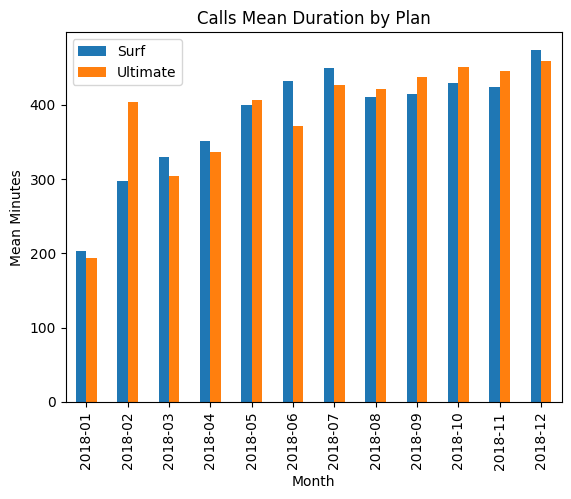

In [31]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.

calls_mean_duration = df_merged.groupby(['plan_name', 'month']).agg(calls_mean=('minutes_used', 'mean')).reset_index()
print(calls_mean_duration)

pivot_table = calls_mean_duration.pivot(index='month', columns='plan_name', values='calls_mean')

pivot_table.plot(kind='bar', title= 'Calls Mean Duration by Plan', xlabel='Month', ylabel='Mean Minutes')

plt.legend(['Surf', 'Ultimate'])
plt.show()


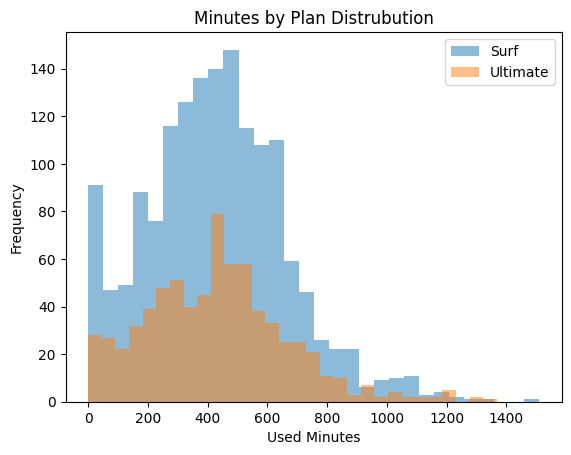

In [32]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.

df_merged['minutes_used'] = df_merged['minutes_used'].fillna(0)

surf_plan_minutes = df_merged[df_merged['plan_name'] == 'Surf']['minutes_used']
ultimate_plan_minutes = df_merged[df_merged['plan_name'] == 'Ultimate']['minutes_used']

plt.hist(surf_plan_minutes, bins=30, alpha=0.5, label='Surf')
plt.hist(ultimate_plan_minutes, bins=30, alpha=0.5, label='Ultimate')

plt.title('Minutes by Plan Distrubution')
plt.xlabel('Used Minutes')
plt.ylabel('Frequency')
plt.legend()
plt.show()

A partir del cálculo de la media y la varianza, veremos si hay diferencias significativas entre ambos planes.

In [33]:

# Calcula la media y la varianza de la duración mensual de llamadas.
# Excluimos los meses con llamadas con valor cero, ya que son artificiales. Al excluirlos evitamos que se distorsionen la media y la varianza y podremos hacer una análisis más certero del comportamiento por plan.

placed_calls = df_merged[df_merged['minutes_used'] > 0]
df_merged_duration = placed_calls.groupby('plan_name')['minutes_used'].agg(['mean','var'])
print(df_merged_duration)



                 mean           var
plan_name                          
Surf       436.802461  52481.561083
Ultimate   435.286517  56387.085163


<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

La plantilla pide la media y la varianza de los *totales mensuales por usuario* por plan. Como antes rellenaste los `minutes_used` faltantes con 0 para graficar, tu media/varianza actual puede estar distorsionada por ceros artificiales. Considera calcular las estadísticas a partir de los totales usuario-mes por plan (y tomar una decisión deliberada sobre si los meses “sin llamadas” se incluyen como 0 o se excluyen) y explica esa elección.

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 2)</b>

✅ Resuelto. La celda 86 filtra placed_calls = df_merged[minutes_used > 0] con comentario explicito sobre la decision ("son artificiales"). La decision es deliberada y bien justificada. ✅
</div>


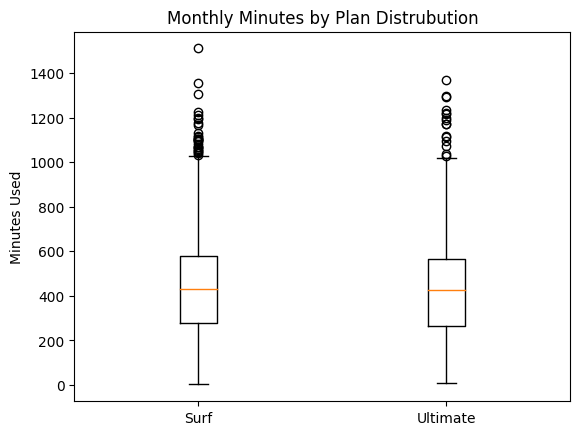

In [34]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

# Siguiendo la misma lógica del paso anterior, solo empleamos las llamadas materializadas.

surf_plan_minutes = placed_calls[placed_calls['plan_name'] == 'Surf']['minutes_used']
ultimate_plan_minutes = placed_calls[placed_calls['plan_name'] == 'Ultimate']['minutes_used']

plt.boxplot([surf_plan_minutes, ultimate_plan_minutes], labels=['Surf', 'Ultimate'])
plt.title('Monthly Minutes by Plan Distrubution')
plt.ylabel('Minutes Used')
plt.show()





<div class="alert alert-block alert-warning">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Problema recurrente: los gráficos de distribución de llamadas se ven afectados porque antes se rellenaron los `minutes_used` faltantes con 0. Considera generar los gráficos a partir de una tabla usuario-mes definida de forma consistente (donde los ceros sean intencionales) o excluir los meses realmente faltantes para que la distribución no se distorsione por ceros artificiales.

</div>


Podemos observar que el comportamiento no difiere demasiado en función del plan. La mediana la vemos casi en el mismo punto (alrededor de 410 - 430 minutos). La caja también es muy similar y los bigotes llegan en ambos caso al mismo número (alrededor de 1010 - 1020). En el plan Surf, no obstante, sí vemos algunos outliers extremos, llevado casi a 1600.

### Mensajes

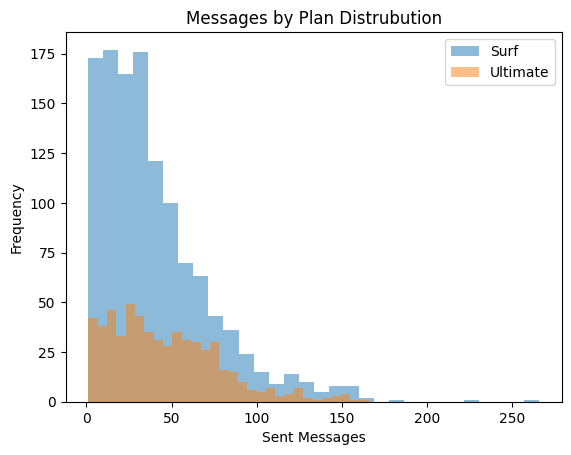

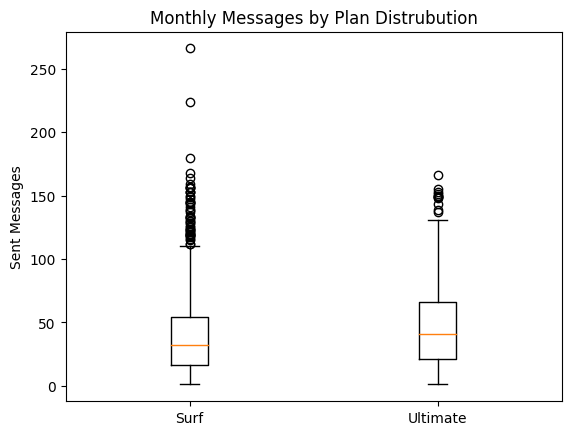

In [35]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan
# Continuando con la lógica de excluir los mensajes con valor cero, procedemos a exluirlos.

sent_messages = df_merged[df_merged['messages_count'] > 0]
surf_plan_messages = sent_messages[sent_messages['plan_name'] == 'Surf']['messages_count']
ultimate_plan_messages = sent_messages[sent_messages['plan_name'] == 'Ultimate']['messages_count']

plt.hist(surf_plan_messages, bins=30, alpha=0.5, label='Surf')
plt.hist(ultimate_plan_messages, bins=30, alpha=0.5, label='Ultimate')

plt.title('Messages by Plan Distrubution')
plt.xlabel('Sent Messages')
plt.ylabel('Frequency')
plt.legend()
plt.show()


surf_plan_messages = sent_messages[sent_messages['plan_name'] == 'Surf']['messages_count']
ultimate_plan_messages = sent_messages[sent_messages['plan_name'] == 'Ultimate']['messages_count']

plt.boxplot([surf_plan_messages, ultimate_plan_messages], labels=['Surf', 'Ultimate'])
plt.title('Monthly Messages by Plan Distrubution')
plt.ylabel('Sent Messages')
plt.show()


En el histograma podemos ver los usuarios del plan Surf tienen una cola muy sesgada a la derecha. La mayoría de usuarios envían entre 0 y 50 mensaje. En el plan Ultimate se aprecia un comportamiento parecido, pero no tan extremo. En ese plan, la mayoría de los clientes envían entre cero y 80 mensajes.
En el boxplot podemos ver diferencias entre la mediana de los dos planes, que es de alrededor de 40, mientras que en Surf es de aproximadamente 30. En cuanto al tamaño de la caja, vemos que es más grande en Ultimate, lo que nos indica mayor varibilidad en este plan que en Surf.
En cuanto a los outliers, en Sufr son extremos, alcanzando casi 300 mensajes.

<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Tu sección de mensajes necesita (1) las estadísticas descriptivas solicitadas (como mínimo la media/varianza/std para los recuentos mensuales de mensajes; idealmente también una comparación mes a mes por plan) y (2) conclusiones escritas en una celda de markdown en lugar de comentarios en el código, para que aparezcan como parte de la narrativa del informe.

</div>


### Internet

            mean  variance   std  median  min   max  count
plan_name                                                 
Surf       16.83     59.47  7.71    17.0  1.0  70.0   1558
Ultimate   17.33     58.49  7.65    17.0  1.0  46.0    719


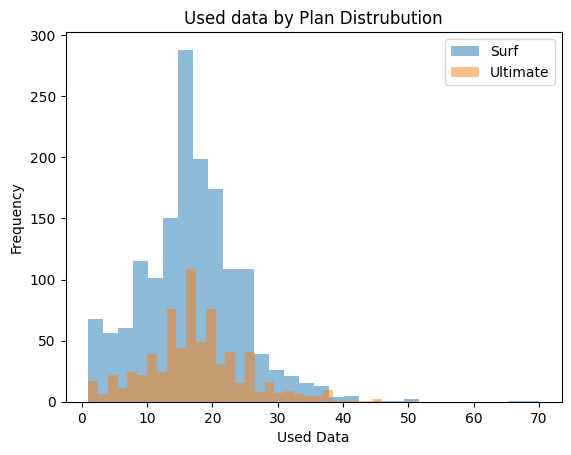

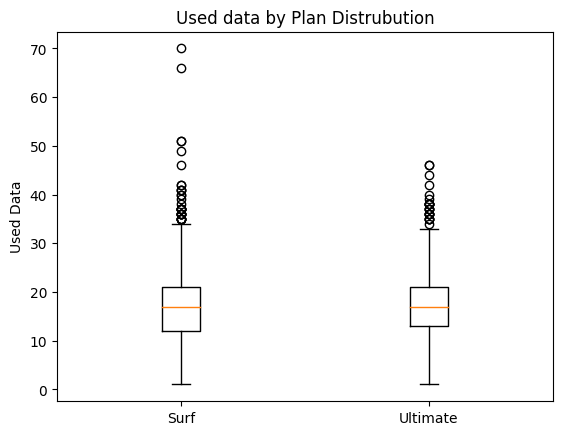

In [45]:
# Compara la cantidad de tráfico de Internet consumido por usuarios por plan

# Continuando con la lógica de no tomar en cuenta los datos artificiales, procedemos a exluirlos.

used_internet = df_merged[df_merged['gb_used'] > 0]


# Añadimos las estadísticas descriptivas:

internet_stats = used_internet.groupby('plan_name')['gb_used'].agg(mean='mean', variance='var', std='std', median='median', min='min', max='max', count='count').round(2)
print(internet_stats)



surf_plan_data = used_internet[used_internet['plan_name'] == 'Surf']['gb_used']
ultimate_plan_data = used_internet[used_internet['plan_name'] == 'Ultimate']['gb_used']




plt.hist(surf_plan_data, bins=30, alpha=0.5, label='Surf')
plt.hist(ultimate_plan_data, bins=30, alpha=0.5, label='Ultimate')

plt.title('Used data by Plan Distrubution')
plt.xlabel('Used Data')
plt.ylabel('Frequency')
plt.legend()
plt.show()



surf_plan_data = used_internet[used_internet['plan_name'] == 'Surf']['gb_used']
ultimate_plan_data = used_internet[used_internet['plan_name'] == 'Ultimate']['gb_used']

plt.boxplot([surf_plan_data, ultimate_plan_data], labels=['Surf', 'Ultimate'])
plt.title('Used data by Plan Distrubution')
plt.ylabel('Used Data')
plt.show()

<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Para el uso de Internet, añade las estadísticas descriptivas que faltan (media/varianza/desviación estándar del consumo mensual por plan, e idealmente una comparación por mes). Ahora mismo solo muestras distribuciones generales, lo cual no cumple completamente con el requisito del resumen estadístico de la plantilla.

</div>


<div class="alert alert-block alert-danger">
<b>Comentario del revisor. (Iteracion 2)</b>

La seccion de Internet (c96) sigue sin las estadisticas descriptivas que pedia el danger de IT1: <b>media, varianza y desviacion estandar del consumo mensual de GB por plan</b>. Solo hay histograma y texto de conclusion — faltan los numeros.

Agrega una celda despues de c96 con algo como:

```python
used_internet = df_merged[df_merged['gb_used'] > 0]
internet_stats = used_internet.groupby('plan_name')['gb_used'].agg(['mean','var','std'])
print(internet_stats)
```

Con eso el danger queda resuelto y el proyecto queda aprobado.
</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 3)</b>

✅ Resuelto. La celda 104 tiene:
- Estadisticas descriptivas (mean, var, std, median, min, max, count) por plan ✅
- Histograma comparativo Surf vs Ultimate ✅
- Boxplot comparativo ✅

Ademas, la conclusion escrita en c107 ya existia y es buena. El analisis de internet esta ahora completamente cubierto. ✅
</div>


Podemos ver que la distrubución del uso de datos es muy similar entre ambos planes, lo cual nos podría indicar que el consumo de datos no está influido por el plan contratado.
En el histograma podemos ver la confirmación de esta observación. La mediana en ambos planes de aproximadamente 18 GB. El tamaño de las cajas es parecido (entre 13 y 21 GB). Los bigotes también muestran similitudes. Sí continuamos viendo los outliers extremos en Surf, alcanzado los 70 o un poco más, inclusive. 

## Ingreso

Procedemos a describir estadísticamente los ingresos de los planes.

            mean  variance    std  median   min     max  count
plan_name                                                     
Surf       60.71   3067.84  55.39   40.36  20.0  590.37   1573
Ultimate   72.31    129.85  11.40   70.00  70.0  182.00    720


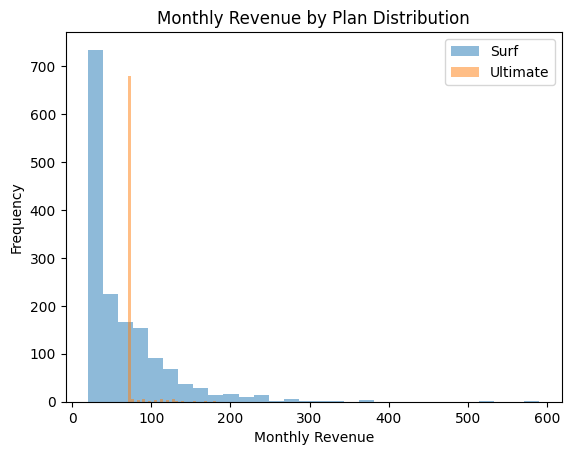

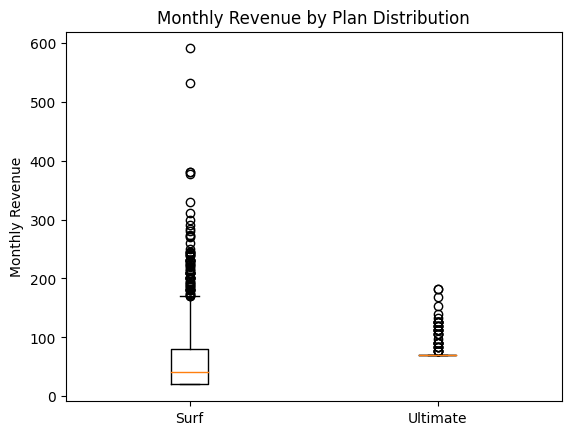

In [37]:


surf_plan_revenue = df_merged[df_merged['plan_name'] == 'Surf']['monthly_revenue']
ultimate_plan_revenue = df_merged[df_merged['plan_name'] == 'Ultimate']['monthly_revenue']


# Añadimos las estadísticas descriptivas:

plans_stats = df_merged.groupby('plan_name')['monthly_revenue'].agg(mean='mean', variance='var', std='std', median='median', min='min', max='max', count='count').round(2)
print(plans_stats)



plt.hist(surf_plan_revenue, bins=30, alpha=0.5, label='Surf')
plt.hist(ultimate_plan_revenue, bins=30, alpha=0.5, label='Ultimate')
plt.title('Monthly Revenue by Plan Distribution')
plt.xlabel('Monthly Revenue')
plt.ylabel('Frequency')
plt.legend()
plt.show()



plt.boxplot([surf_plan_revenue, ultimate_plan_revenue], labels=['Surf', 'Ultimate'])
plt.title('Monthly Revenue by Plan Distribution')
plt.ylabel('Monthly Revenue')
plt.show()




<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Para ingresos, los gráficos son útiles, pero la plantilla también solicita una descripción estadística. Añade una pequeña tabla de estadísticas descriptivas por plan (al menos la media, la varianza y la desviación estándar de `monthly_revenue`) para respaldar tu comparación.

</div>


Según las observaciones de las estadísticas descriptivas, vemos diferencias importantes entre los dos planes. En cuanto a la media, vemos que Ultimate genera más ingresos que Surf. Si vemos la varianza, vemos que en Surf los datos están mucho más dispersos, lo que nos indica que en este plan se paga más por excedentes al tener inclusiones mucho más limitadas que Ultimate, así que tiene sentido ese resultado. Si vemos los min. y max., podemos observas también aquí los outliers extremos de Surf que veíamos en los gráficos de consumo anteriores. Observando la mediana, vemos que en Surf es menor que en Ultimate (Ultimate se concentra en 70, que es el fee mensual, mientras que en Surf es de 40, cuando su fee mensual es de 20, lo que nos indica que gastan más, adicional a su pago mensual).

<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Problema recurrente: actualmente las conclusiones se basan solo en los gráficos. Por favor, respalda la interpretación de ingresos con las estadísticas descriptivas solicitadas (p. ej., media y variabilidad por plan) para que el argumento esté sustentado en evidencia.

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 2)</b>

✅ Resuelto. La celda 101 tiene estadisticas muy completas de revenue por plan: media, varianza, std, mediana, min, max y count. Mucho mejor que la IT1. ✅
</div>


## Prueba las hipótesis estadísticas

Vamos a probar la hipótesis para averiguar si hay diferencias o no en los ingresos según el plan de cada usuario.

Procedemos a las pruebas de hipótesis.

In [38]:

# Prueba las hipótesis
# Hipótesis nula: No hay diferencia en el ingreso promedio mensual entre los usuarios de los planes Ultimate y Surf.
# Hipótesis altenativa: Sí hay diferencia en el ingreso promedio mensual entre los usuarios de los planes Ultimate y Surf

#Usamos la prueba test de dos muestras independientes porque son dos grupos distintos y el comportamiento de uno no influye en el comportamiento del otro.
# Valor alfa = 0.05


from scipy import stats

surf_plan_revenue = df_merged[df_merged['plan_name'] == 'Surf']['monthly_revenue']
ultimate_plan_revenue = df_merged[df_merged['plan_name'] == 'Ultimate']['monthly_revenue']

alpha = 0.05

results = stats.ttest_ind(surf_plan_revenue, ultimate_plan_revenue, equal_var =False, nan_policy='omit')
print('p-value:' , results.pvalue)

if results.pvalue < alpha:
    print('Rechazamos H0: No hay diferencia en el ingreso promedio mensual entre los usuarios de ambos planes')
else:
    print('No podemos rechazar H0: No hay evidencia suficiente que nos indique que hay diferencia')

    

p-value: 3.1703905481135734e-15
Rechazamos H0: No hay diferencia en el ingreso promedio mensual entre los usuarios de ambos planes


Observando el valor de p, vemos que el resultado (3.17) es menor a la significancia estadística y podemos deducir que sí hay diferencia en el ingreso promedio mensual entre los usuarios de los dos planes, por lo tanto, rechazamos la hipótesis nula. Estamos hablando de un ingreso promedio de 70 USD para Ultimate versus 60 USD de Surf. No obstante, para tomar decisiones de negocio, creo que se debería de seguir analizando el comportamiento de ambos planes, ya sea por regiones, perfiles de usuarios, etc. antes de tomar decisiones de mayor impacto, como una inversión. 

<div class="alert alert-block alert-warning">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Agrega una breve interpretación que conecte el p-value con la pregunta de negocio: indica qué plan tiene el mayor ingreso mensual promedio en tu muestra y explica qué implica rechazar H0 (una diferencia estadísticamente significativa en el ingreso promedio, no necesariamente significancia práctica).

</div>


Ahora probamos la hipótesis de que el ingreso promedio de los usuarios del área NY-NJ es diferente al de otras regiones.

Procedemos a las pruebas de hipótesis.

In [39]:
# Prueba las hipótesis

# Hipótesis nula: No hay diferencia en el ingreso promedio mensual entre los usuarios del área NY-NJ y usuarios de otras regiones.
# Hipótesis altenativa: Sí hay diferencia en el ingreso promedio mensual entre los usuarios del área NY-NJ y usuarios de otras regiones

#Usamos la prueba test de dos muestras independientes porque son dos grupos distintos y el comportamiento de uno no influye en el comportamiento del otro.
# Valor alfa = 0.05




df_merged = df_merged.merge(df_users[['user_id', 'city']], on='user_id', how='left')

df_merged['is_ny_nj'] = df_merged['city'].str.contains('NY-NJ', na=False)


from scipy import stats

ny_nj_revenue = df_merged[df_merged['is_ny_nj'] == True]['monthly_revenue']
other_regions_revenue = df_merged[df_merged['is_ny_nj'] == False]['monthly_revenue']


# Añadimos las medias de ambos grupos para completar la prueba de hipótesisi

ny_nj_mean = ny_nj_revenue.mean()
other_regions_mean = other_regions_revenue.mean()

print(ny_nj_mean)
print(other_regions_mean)

alpha = 0.05

results = stats.ttest_ind(ny_nj_revenue, other_regions_revenue, equal_var =False, nan_policy='omit')
print('p-value:' , results.pvalue)

if results.pvalue < alpha:
    print('Rechazamos H0: Sí hay diferencia en el ingreso promedio mensual entre loS usuarios del área NY-NJ')
else:
    print('No podemos rechazar H0: No hay evidencia suficiente que nos indique que hay diferencia')





59.921352785145885
65.2227713987474
p-value: 0.0335256158853001
Rechazamos H0: Sí hay diferencia en el ingreso promedio mensual entre loS usuarios del área NY-NJ


Para el análisis de la región, rechazamos la hipótesis nula, dado que sí hay diferencia en el ingreso promedio mensual de los usuarios de NY-NJ versus el resto de las regiones, no obstante, el valor de p, 0.03 está cerca del umbral de 0.05, lo que nos indica que aunque hay diferencia esta es moderada y hay que ser cautelosos con las decisiones que tomemos en cuanto a planes de inversión por región. En la media podemos ver que el área de NY-NJ es de 59.9, mientras que la media de las otras regiones es de 65.2, lo que nos ayuda también a seguir analizando datos adicionales, por ejemplo, dividir en mayor número de regiones y volver a comparar, antes de abordar el plan de inversión en publicidad basados solo en las observaciones de estos datos.

<div class="alert alert-block alert-warning">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Para completar la prueba de hipótesis regional, informa las medias de los grupos (NY-NJ vs otras regiones) e interpreta la dirección de la diferencia. También puedes señalar que p≈0.033 con alpha=0.05 es estadísticamente significativo, pero está bastante cerca del umbral, por lo que la evidencia es moderada.

</div>


## Conclusión general



1. Limpieza y preparación de los datos. Lo más relevante de este paso fue asegurarme de que contaba con la información completa en cada dataset, lo que me permitiría seguir avanzado con mayor confianza hacia los pasos siguientes.
2. Integración de los datos de todos los datasets. Al fusionar la información, esta cobraba más sentido, lo que hacía más fácil ir analizando los comportamientos de los grupos.
3. Descubrimiento de los patrones de consumo entre usuarios de los distintos planes. Si bien hemos visto que los usuarios de Ultimate generan un mayor ingreso promedio que Surf, vale la pena seguir indagando por el potencial de ingresos de Surf, dada la variabilidad observada. Hemos visto que estos usuarios pagan más por consumos adicionales dadas las limitaciones de su plan.
4. Finalmente, dados los resultados de ingresos entre ambos grupos, la empresa se podría plantear dos opciones: modificar las condiciones actuales de los usuarios Ultimate (teniendo en cuenta si se puede asumir incremento en el churn como consecuencia de que los usuarios ya no lo perciban con el "Plan Premium Todo Incluido"), de manera que no tengan tanto margen con su plan y se vean obligados a realizar consumos adicionales que generen más revenue a la empresa o bien, dirigir el ajuste en inversión de publicidad hacia la captación y fidelización de los usuarios Surf, que es el grupo donde realmente se generan ingresos variables alcanzando límites altos por consumos adicionales, dado lo limitado o básico que es su plan.
5. En cuanto al análisis por regiones, según los datos observados, si bien hay una diferencia, esta no es tan amplia para sustentar planes de inversión, así que valdría la pena ampliar el análisis a otras regiones para revisar si estos comportamientos se producen en otras zonas geográficas y, de paso, optimizar la inversión en aquellas zonas donde realmente se vaya a tener un retorno de lo que se invierta en el plan de publicidad.
   



<div class="alert alert-block alert-danger">
<b>Reviewer's comment, Iteration 1</b> <a class="tocSkip"></a>

Esta sección aún contiene la guía de la plantilla entre corchetes. Por favor, elimina el texto entre corchetes y deja únicamente tus conclusiones finales (resumiendo los supuestos/decisiones clave y los hallazgos principales).

</div>


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteracion 2)</b>

✅ Resuelto. La conclusion (c116) tiene texto propio con 5 puntos bien estructurados que cubren preparacion, integracion, comportamiento, hipotesis y recomendacion de negocio. No hay brackets. ✅
</div>


<div class="alert alert-block alert-warning">
<b>Review General. (Iteracion 2) — Resumen final</b>

Muy buen avance: 7 de los 8 dangers de IT1 quedaron resueltos. Para poder aprobar, necesitas resolver <b>un unico punto</b> (en rojo):

1. <b>Estadisticas de Internet (c97 danger):</b> agrega una celda con media, varianza y std de gb_used agrupado por plan. El histograma y la conclusion escrita ya estan — solo faltan los numeros.

Como recomendaciones adicionales (amarillo):
- Mueve fillna(0) de minutes_used y calls_count a la celda 75 (antes del calculo de revenue).
- Elimina el bracket de plantilla en la celda 2.

Con esa sola celda de estadisticas de Internet el proyecto queda aprobado! 💪
</div>


<div class="alert alert-block alert-success">
<b>Review General. (Iteracion 3) — Resumen final</b>

El proyecto esta <b>aprobado</b>, Cristina! 🎉

A lo largo de las tres iteraciones resolviste todos los puntos criticos:
- ✅ churn_date a datetime con NaT + flag has_churned
- ✅ Llamadas de 0 min: decision documentada y justificada
- ✅ Validaciones de mb_used (negativos, ceros, estadisticas)
- ✅ gb_included sin ceil (division exacta de MB/1024)
- ✅ Stats de llamadas con decision deliberada sobre meses sin actividad
- ✅ Stats de ingresos (mean/var/std/median/min/max/count)
- ✅ Conclusion general sin brackets
- ✅ Stats de internet completas (mean/var/std/median/min/max/count) + histograma + boxplot

Observaciones en amarillo para futuros proyectos:
- Elimina el bracket de la celda 2.
- Aplica ceil por llamada individual con duration_rounded.
- Haz Restart & Run All para execution counts consecutivos.

Muy buen trabajo en las tres iteraciones! 🚀
</div>
